# Research Activity
Create an example to generate anomalies on surfaces. For example, the MVTec AD Dataset contains samples of defects applied to train defect’s detection models for AI visual inspections. This research activity aims to create synthetic defects in surface images to be used in anomaly detection. Thus, choose one kind of defect that you prefer to be automatically created (cracks, stains, discoloration, etc.) and try to generate this defect on any surface.


# STEP 1 - Runtime configuration

In [60]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("Warning: CPU detected. Reduce N_CRACKS if generation is too slow.")

Device: cuda


# Step 2 - Installation of Packages

In [61]:
%pip -q install diffusers transformers accelerate safetensors scikit-image opencv-python-headless
%pip -q install -U torchao

# Step 3 - Image Download




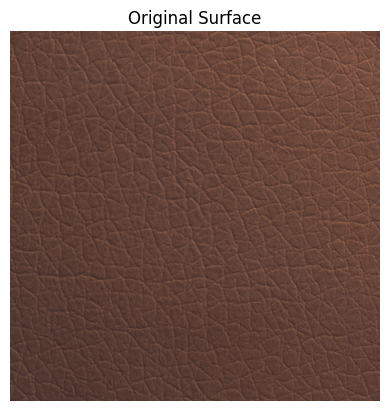

Successfully downloaded 1 image to /content/surfaces/047.png


In [62]:
import os, urllib.request
import matplotlib.pyplot as plt
from PIL import Image

# Your specific GitHub details
GITHUB_USER = "parpi13"
GITHUB_REPO = "mvtec-sample"
BRANCH = "main"
IMG_NAME = "047.png"

GOOD_DIR = "/content/surfaces"
os.makedirs(GOOD_DIR, exist_ok=True)

# Build the URL and download
url = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/{IMG_NAME}"
dst = os.path.join(GOOD_DIR, IMG_NAME)

print(f"Downloading {url}...")
urllib.request.urlretrieve(url, dst)

# Set up the path variable that the rest of your notebook expects
good_paths = [dst]

# Show the image to confirm it worked
img = Image.open(good_paths[0]).convert("RGB")
plt.imshow(img)
plt.axis("off")
plt.title("Original Surface")
plt.show()

print(f"Successfully downloaded 1 image to {dst}")

# Step 4 - Difussion Model

In [63]:
from diffusers import AutoPipelineForText2Image

model_id = "stabilityai/sd-turbo"
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = AutoPipelineForText2Image.from_pretrained(
    model_id,
    torch_dtype=dtype
).to(device)
print("Loaded:", model_id)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Loaded: stabilityai/sd-turbo


# Step 5 - Generating the defect

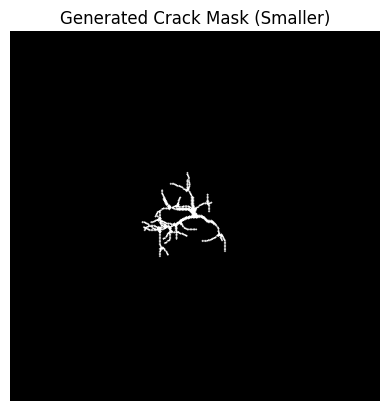

In [67]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt

# Initialize a blank canvas (black background)
mask = np.zeros((512, 512), dtype=np.uint8)

def draw_branch(img_mask, start_x, start_y, length, thickness, angle):
    """Recursively draws a jagged crack line."""
    x, y = start_x, start_y
    for i in range(length):
        # Random walk: change angle slightly
        angle += random.uniform(-0.4, 0.4)
        x += int(np.cos(angle) * 3) # Reduced step size for a tighter crack
        y += int(np.sin(angle) * 3)

        # Stop if out of bounds (512x512)
        if x < 0 or x >= 512 or y < 0 or y >= 512:
            break

        # Draw the segment (tapering thickness)
        t = int(thickness * (1 - i / length)) + 1
        cv2.circle(img_mask, (x, y), t, 255, -1)

        # Randomly branch out
        if random.random() < 0.05 and length > 10:
            draw_branch(img_mask, x, y, length//2, max(1, thickness-1), angle + random.uniform(0.5, 1.2))
            draw_branch(img_mask, x, y, length//2, max(1, thickness-1), angle - random.uniform(0.5, 1.2))

# Start the crack in the center with a few main branches
center_x, center_y = 256, 256
for _ in range(4): # Reduced from 5 to 4 main branches
    angle = random.uniform(0, 2 * np.pi)
    # Smaller length and thickness
    draw_branch(mask, center_x, center_y, length=25, thickness=2, angle=angle)

# Save the mask so we can use it in Step 6
cv2.imwrite("/content/crack_mask.png", mask)

# Show the mask
plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.title("Generated Crack Mask (Smaller)")
plt.show()

# Step 6 - Composite the defect on the leather


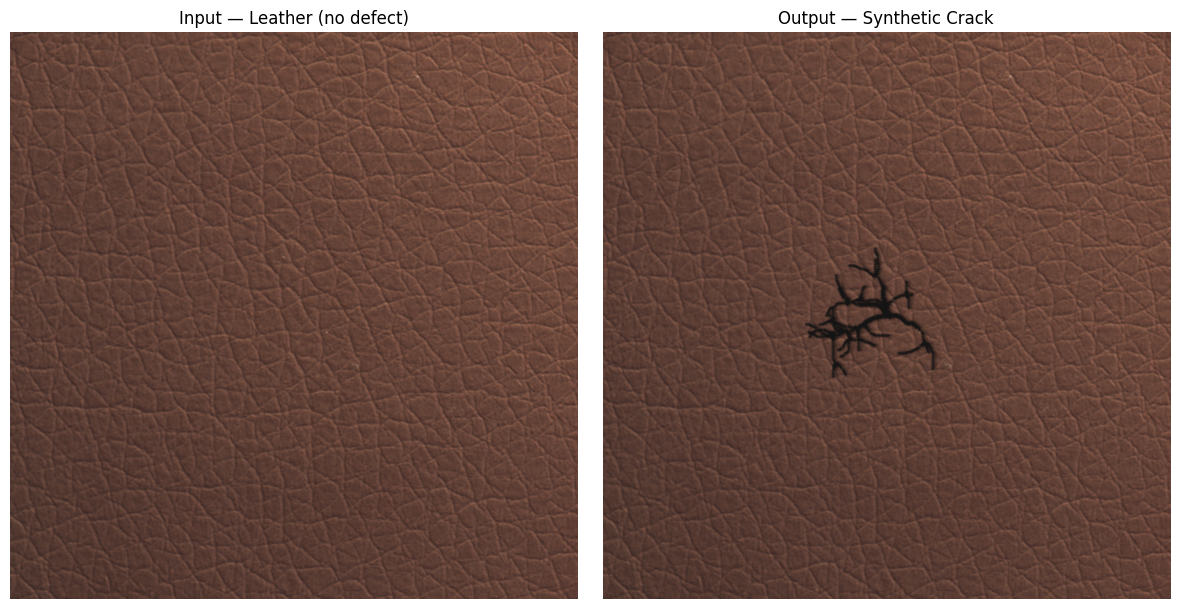

In [68]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load the original leather image
orig = Image.open(good_paths[0]).convert("RGB")
leather_arr = np.array(orig).astype(np.float32)
H, W = leather_arr.shape[:2]

# Load the mask generated in Step 5
mask = cv2.imread("/content/crack_mask.png", cv2.IMREAD_GRAYSCALE)

# --- FIX: Resize mask to match the leather image dimensions ---
if mask.shape != (H, W):
    mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)

# 1. Blur the mask to make edges soft
alpha = cv2.GaussianBlur(mask, (5, 5), 0).astype(np.float32) / 255.0

# 2. Create the crack color (dark brown/black)
crack_color = np.array([20, 20, 20], dtype=np.float32)
crack_layer = np.ones_like(leather_arr, dtype=np.float32) * crack_color

# 3. Create a shadow layer to give the crack depth (shift the mask)
shift = 4 # Scaled up shift for the larger image
shadow_mask = np.roll(mask, shift, axis=1)
shadow_alpha = cv2.GaussianBlur(shadow_mask, (11, 11), 0).astype(np.float32) / 255.0

# 4. Composite the shadow and the crack onto the leather
synth_arr = leather_arr.copy()

# Apply shadow first
synth_arr = synth_arr * (1 - shadow_alpha[..., None] * 0.6) + (synth_arr * 0.3) * (shadow_alpha[..., None] * 0.6)

# Apply the crack body
alpha_3d = np.repeat(alpha[..., None], 3, axis=2)
synth_arr = synth_arr * (1 - alpha_3d) + crack_layer * alpha_3d

# Convert back to image
synth = Image.fromarray(np.clip(synth_arr, 0, 255).astype(np.uint8))

# Save
orig.save("/content/input_no_defect.png")
synth.save("/content/output_synthetic_defect.png")

# Define bounding box variables (px, py, cw, ch) for the kNN evaluator
y_coords, x_coords = np.where(mask > 0)
if len(x_coords) > 0:
    px, py = int(x_coords.min()), int(y_coords.min())
    cw, ch = int(x_coords.max() - px), int(y_coords.max() - py)
else:
    px, py, cw, ch = W//2 - 50, H//2 - 50, 100, 100 # fallback

# Display the results
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(orig)
ax[0].set_title("Input — Leather (no defect)")
ax[0].axis("off")

ax[1].imshow(synth)
ax[1].set_title("Output — Synthetic Crack")
ax[1].axis("off")

plt.tight_layout()
plt.savefig("/content/synthetic_defect_figure.png", dpi=150, bbox_inches="tight")
plt.show()

# Step 7 - Suggested Evaluation

In [69]:
from sklearn.neighbors import NearestNeighbors
import torch
import numpy as np
from torchvision.models import resnet18, ResNet18_Weights

print("--- Downstream Anomaly Detection (kNN) ---")

# 1. Feature extractor
weights = ResNet18_Weights.DEFAULT
feature_model = resnet18(weights=weights)
feature_model.fc = torch.nn.Identity()
feature_model = feature_model.to(device).eval()
preprocess = weights.transforms()

@torch.no_grad()
def extract_single_feature(img):
    t = preprocess(img.convert("RGB")).unsqueeze(0).to(device)
    return feature_model(t).float().cpu().numpy()[0]

# 2. Extract features from patches of the normal image
def get_patch_features(image, patch_size=None):
    W, H = image.size
    if patch_size is None:
        patch_size = min(W, H) // 4
    feats = []
    for y in range(0, H - patch_size + 1, patch_size):
        for x in range(0, W - patch_size + 1, patch_size):
            patch = image.crop((x, y, x + patch_size, y + patch_size))
            patch = patch.resize((224, 224))
            feats.append(extract_single_feature(patch))
    return np.array(feats), patch_size

normal_feats, patch_size = get_patch_features(orig)
print(f"Patch size: {patch_size}px   |   Normal patches: {normal_feats.shape}")

# 3. Fit kNN on normal patches
knn = NearestNeighbors(n_neighbors=3)
knn.fit(normal_feats)

# 4. Build the test crops — use the SAME patch_size as the training patches
#    so the comparison is apples-to-apples
test_size = patch_size
# center the crop on the pasted crack region
cx = px + cw // 2
cy = py + ch // 2
x0 = max(0, min(W - test_size, cx - test_size // 2))
y0 = max(0, min(H - test_size, cy - test_size // 2))

normal_test_patch = orig.crop((x0, y0, x0 + test_size, y0 + test_size)).resize((224, 224))
defect_test_patch = synth.crop((x0, y0, x0 + test_size, y0 + test_size)).resize((224, 224))

normal_vec = extract_single_feature(normal_test_patch).reshape(1, -1)
defect_vec = extract_single_feature(defect_test_patch).reshape(1, -1)

normal_score = knn.kneighbors(normal_vec)[0].mean()
defect_score = knn.kneighbors(defect_vec)[0].mean()

print(f"Distance (Normal patch): {normal_score:.4f}")
print(f"Distance (Defect patch): {defect_score:.4f}")

if defect_score > normal_score:
    print("Result: The anomaly detector successfully flagged the synthetic defect.")
else:
    print("Result: The defect was not detected.")

--- Downstream Anomaly Detection (kNN) ---
Patch size: 256px   |   Normal patches: (16, 512)
Distance (Normal patch): 3.2057
Distance (Defect patch): 9.5079
Result: The anomaly detector successfully flagged the synthetic defect.
